# 01 · Fase A: disección instrumentada de SAM ViT-B

Completa el *architecture teardown* que pide el enunciado, sobre `facebook/sam-vit-base` y en la máquina del equipo (CPU):

| Pedido del enunciado | Qué se hace aquí |
|---|---|
| Parámetros por bloque | Conteo exacto por cada uno de los 12 bloques del ViT, el cuello, el codificador de prompts y cada parte del decodificador |
| FLOPs por bloque | **Medidos** con `torch.utils.flop_counter` y contrastados con la fórmula analítica del E1 (930.38 GFLOPs) |
| Visualización de características intermedias | PCA a 3 componentes de la salida de los bloques 0, 2, 5, 8, 11 y del cuello, en SAR y en una imagen natural |
| Mapa del campo receptivo | **Campo receptivo efectivo** medido por gradiente (Luo et al., 2016) en los bloques 1, 2, 5 y 11 |
| Latencia y memoria | Perfilado etapa por etapa del **pipeline SAR completo** en los 9 chips del E1. Reemplaza los valores `[pendiente]` del E1 |

**Contexto de medición.** CPU AMD Ryzen 7 5700X (8 núcleos, 8 hilos de PyTorch) y GPU NVIDIA GeForce RTX 3070 (8 GB), con la máquina dedicada. Los FLOPs y los parámetros no dependen del hardware.

In [1]:
import json
import sys
import time
from pathlib import Path

sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from inf659sam import config, data, faseA
from inf659sam.baseline import auto_prompts, iou_components, otsu_masks
from inf659sam.cache import save_json
from inf659sam.sam_utils import SamWrapper

config.setup_runtime(seed=0)
ENV = config.environment_report()
print(json.dumps(ENV, indent=1))
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9})
mem0 = faseA.rss_mib()
t0 = time.perf_counter()
sam = SamWrapper(device="cpu")
t_load = time.perf_counter() - t0
mem_model = faseA.rss_mib()
model = sam.model
vc = model.config.vision_config
print(f"Modelo cargado en {t_load:.1f} s | atención: {model.config._attn_implementation}")
print("window_size:", vc.window_size, "| global_attn_indexes:", vc.global_attn_indexes,
      "| hidden:", vc.hidden_size, "| capas:", vc.num_hidden_layers, "| parche:", vc.patch_size)
RESULT = {"entorno": ENV}

Entorno: {'seed': 0, 'torch_threads': 8}


{
 "python": "3.14.7",
 "platform": "Windows-11-10.0.26200-SP0",
 "cpu": "AMD64 Family 25 Model 33 Stepping 2, AuthenticAMD",
 "ram_gb": 31.9,
 "torch": "2.14.1+cu130",
 "transformers": "5.19.0",
 "numpy": "2.5.3",
 "scipy": "1.18.1",
 "skimage": "0.26.0",
 "device": "cuda",
 "gpu": "NVIDIA GeForce RTX 3070",
 "cuda": "13.0",
 "torch_threads": 8,
 "model_id": "facebook/sam-vit-base",
 "model_revision": "70c1a07f894ebb5b307fd9eaaee97b9dfc16068f"
}


Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Loading weights:  22%|██▏       | 70/314 [00:00<00:00, 661.25it/s]

Loading weights: 100%|██████████| 314/314 [00:00<00:00, 1665.97it/s]

Modelo cargado en 3.3 s | atención: sdpa
window_size: 14 | global_attn_indexes: [2, 5, 8, 11] | hidden: 768 | capas: 12 | parche: 16


## 1. Parámetros por bloque

In [2]:
rows = faseA.param_table(model)
total = sum(p.numel() for p in model.parameters())
df_p = pd.DataFrame(rows)
df_p["params"] = df_p["params"].astype(int)
print(f"Total: {total:,} parámetros | suma de la tabla: {df_p['params'].sum():,}")
enc = sum(p.numel() for p in model.vision_encoder.parameters())
dec = sum(p.numel() for p in model.mask_decoder.parameters())
pe = sum(p.numel() for p in model.prompt_encoder.parameters())
print(f"Codificador de imagen {enc:,} ({100*enc/total:.2f} %) | prompts {pe:,} | decodificador {dec:,} ({100*dec/total:.2f} %) | razón {enc/dec:.1f}")
RESULT["parametros"] = {"total": total, "vision_encoder": enc, "prompt_encoder": pe, "mask_decoder": dec,
                        "razon_encoder_decoder": enc / dec, "por_bloque": rows}
df_p.style.format({"params": "{:,}", "pct_total": "{:.3f}"})

Total: 93,735,728 parámetros | suma de la tabla: 93,735,728
Codificador de imagen 89,670,912 (95.66 %) | prompts 6,476 | decodificador 4,058,340 (4.33 %) | razón 22.1


,bloque,params,pct_total
0,vision_encoder.patch_embed,"590,592",0.630
1,vision_encoder.pos_embed,"3,145,728",3.356
2,vision_encoder.layers.0 (ventana 14x14),"7,091,328",7.565
3,vision_encoder.layers.1 (ventana 14x14),"7,091,328",7.565
4,vision_encoder.layers.2 (global),"7,104,128",7.579
5,vision_encoder.layers.3 (ventana 14x14),"7,091,328",7.565
6,vision_encoder.layers.4 (ventana 14x14),"7,091,328",7.565
7,vision_encoder.layers.5 (global),"7,104,128",7.579
8,vision_encoder.layers.6 (ventana 14x14),"7,091,328",7.565
9,vision_encoder.layers.7 (ventana 14x14),"7,091,328",7.565


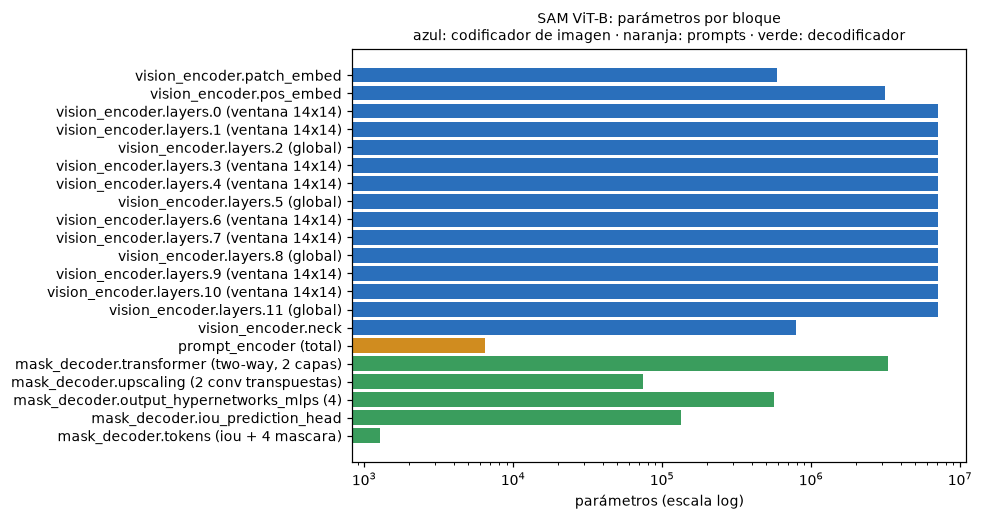

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.8))
colors = ["#2a6fbb" if r.startswith("vision") else ("#d08c1f" if r.startswith("prompt") else "#3a9d5d") for r in df_p["bloque"]]
ax.barh(df_p["bloque"], df_p["params"], color=colors)
ax.set_xscale("log")
ax.invert_yaxis()
ax.set_xlabel("parámetros (escala log)")
ax.set_title("SAM ViT-B: parámetros por bloque\nazul: codificador de imagen · naranja: prompts · verde: decodificador", fontsize=9)
plt.tight_layout()
plt.savefig(config.FIG_DIR / "faseA_parametros_por_bloque.png")
plt.show()

## 2. FLOPs medidos por bloque frente a la fórmula analítica

Se cuenta con `FlopCounterMode` sobre una instancia con atención *eager*, donde las multiplicaciones de matrices de la atención son operaciones explícitas, y una pasada del codificador sobre un chip SAR real. La convención es la misma del E1: 2 FLOPs por multiplicación-suma.

In [4]:
chip_ref = "Somalia_12849"
d = data.load_chip(chip_ref)
om = otsu_masks(d["vv"], d["vh"])
pts, lbs, npos = auto_prompts(om["opened"], om["sensor_valid"])
pre = sam.preprocess(SamWrapper.sar_to_rgb(d["vv"], d["vh"]))

eager = SamWrapper(attn_implementation="eager")
emb_ref = eager.embed(pre["pixel_values"])
p_t, l_t = eager.prompt_tensors(pts, lbs, pre["original_sizes"][0], pre["reshaped_input_sizes"][0])
dv = eager.device
fl = faseA.measure_flops(eager.model, pre["pixel_values"],
                         decode_fn=lambda: eager.model(image_embeddings=emb_ref.to(dv), input_points=p_t.to(dv),
                                                       input_labels=l_t.to(dv), multimask_output=True))
an = faseA.analytical_flops(vc)
print("claves del contador (muestra):", fl["raw_keys_sample"])
filas = []
for i in range(vc.num_hidden_layers):
    tipo = "global" if i in vc.global_attn_indexes else "ventana"
    a = an["global_block"] if tipo == "global" else an["window_block"]
    m = fl["per_layer"].get(i, np.nan)
    filas.append({"bloque": i, "tipo": tipo, "GFLOPs_medidos": m / 1e9, "GFLOPs_formula_E1": a / 1e9,
                  "diferencia_pct": 100 * (m - a) / a})
df_f = pd.DataFrame(filas)
print(f"Codificador completo medido: {fl['encoder_total']/1e9:.2f} GFLOPs | fórmula E1: {an['total']/1e9:.2f} GFLOPs "
      f"| diferencia {100*(fl['encoder_total']-an['total'])/an['total']:+.1f} %")
print(f"patch_embed {fl['patch_embed']/1e9:.2f} | cuello {fl['neck']/1e9:.2f} | "
      f"prompts+decodificador {fl['prompt_mas_decoder_total']/1e9:.2f} GFLOPs")
RESULT["flops"] = {"medido_codificador": fl["encoder_total"], "formula_E1_codificador": an["total"],
                   "medido_por_bloque": fl["per_layer"], "patch_embed": fl["patch_embed"], "neck": fl["neck"],
                   "prompt_mas_decoder": fl["prompt_mas_decoder_total"],
                   "formula_bloque_global": an["global_block"], "formula_bloque_ventana": an["window_block"]}
df_f.round(3)

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Loading weights:  25%|██▍       | 77/314 [00:00<00:00, 752.99it/s]

Loading weights:  49%|████▊     | 153/314 [00:00<00:00, 754.30it/s]

Loading weights: 100%|██████████| 314/314 [00:00<00:00, 1483.24it/s]

W1012 02:31:04.456000 28044 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


claves del contador (muestra): ['SamVisionEncoder.patch_embed', 'Global', 'SamVisionEncoder.patch_embed.projection', 'SamVisionEncoder', 'SamVisionEncoder.layers.0.attn.qkv', 'SamVisionEncoder.layers.0', 'SamVisionEncoder.layers.0.attn', 'SamVisionEncoder.layers.0.attn.proj']
Codificador completo medido: 972.08 GFLOPs | fórmula E1: 930.38 GFLOPs | diferencia +4.5 %
patch_embed 4.83 | cuello 6.44 | prompts+decodificador 3.69 GFLOPs


,bloque,tipo,GFLOPs_medidos,GFLOPs_formula_E1,diferencia_pct
0,0,ventana,64.937,60.932,6.572
1,1,ventana,64.937,60.932,6.572
2,2,global,110.327,109.522,0.735
3,3,ventana,64.937,60.932,6.572
4,4,ventana,64.937,60.932,6.572
5,5,global,110.327,109.522,0.735
6,6,ventana,64.937,60.932,6.572
7,7,ventana,64.937,60.932,6.572
8,8,global,110.327,109.522,0.735
9,9,ventana,64.937,60.932,6.572


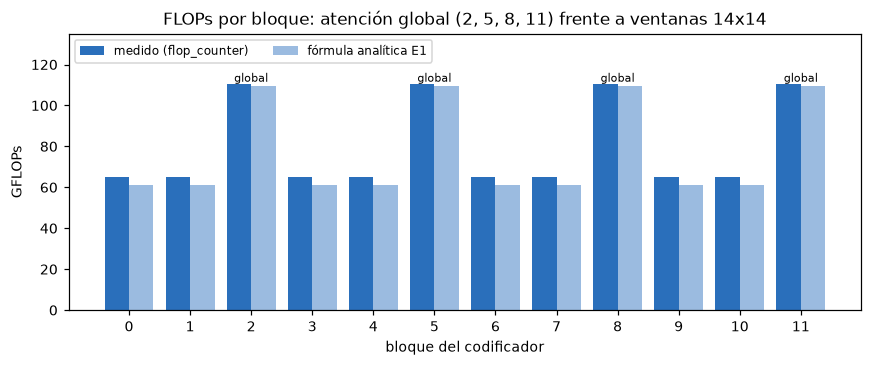

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(vc.num_hidden_layers)
ax.bar(x - 0.2, df_f["GFLOPs_medidos"], 0.4, label="medido (flop_counter)", color="#2a6fbb")
ax.bar(x + 0.2, df_f["GFLOPs_formula_E1"], 0.4, label="fórmula analítica E1", color="#9bbbe0")
for i in vc.global_attn_indexes:
    ax.annotate("global", (i, df_f.loc[i, "GFLOPs_medidos"]), ha="center", va="bottom", fontsize=7)
ax.set_xticks(x)
ax.set_ylim(0, 135)
ax.set_xlabel("bloque del codificador")
ax.set_ylabel("GFLOPs")
ax.set_title("FLOPs por bloque: atención global (2, 5, 8, 11) frente a ventanas 14x14")
ax.legend(loc="upper left", ncol=2, fontsize=8)
plt.tight_layout()
plt.savefig(config.FIG_DIR / "faseA_flops_por_bloque.png")
plt.show()

## 3. Latencia y memoria del pipeline SAR completo

Se reemplazan los campos `[latencia_pipeline_SAR_ms = pendiente]` y `[memoria_pipeline_SAR_GiB = pendiente]` del E1. Se usan los 9 chips evaluables del E1, cada etapa por separado y con una pasada de calentamiento, en CPU y en GPU.

In [6]:
valid = data.read_split("valid")
chips9 = [c for c in data.first_chip_per_region(valid) if c != "Ghana_5079"]


def perfilar(w):
    timer = faseA.StageTimer()
    _ = w.embed(pre["pixel_values"])  # calentamiento
    ious = {}
    for chip in chips9:
        with timer("1 lectura GeoTIFF"):
            dd = data.load_chip(chip)
        with timer("2 Otsu + apertura"):
            o = otsu_masks(dd["vv"], dd["vh"])
        with timer("3 prompts automáticos"):
            p, l, k = auto_prompts(o["opened"], o["sensor_valid"])
        with timer("4 normalización a RGB"):
            rgb = SamWrapper.sar_to_rgb(dd["vv"], dd["vh"])
        with timer("5 preprocesado SAM (1024 px)"):
            pr = w.preprocess(rgb)
        with timer("6 codificador de imagen"):
            e = w.embed(pr["pixel_values"])
        with timer("7 prompts + decodificador + posproceso"):
            r = w.decode(e, p, l, pr["original_sizes"], pr["reshaped_input_sizes"], multimask=True)
        with timer("8 evaluación IoU"):
            lab = dd["label"]
            ious[chip] = iou_components(r["masks"][int(np.argmax(r["scores"]))], lab == 1, lab != -1)["iou"]
    return timer.summary(), ious


lat, ious = perfilar(sam)
mem_end = faseA.rss_mib()
RESULT["latencia_pipeline_SAR"] = {"etapas": lat, "total_ms_media": sum(v["media_ms"] for v in lat.values()),
                                   "chips": chips9, "hilos": torch.get_num_threads(), "dispositivo": "cpu"}
RESULT["memoria"] = {"antes_de_cargar_mib": mem0, "con_modelo_mib": mem_model, "final_mib": mem_end}
RESULT["iou_control_9chips"] = ious
tabla = {"etapa": sorted(lat), "CPU media (ms)": [lat[k]["media_ms"] for k in sorted(lat)],
         "CPU desv (ms)": [lat[k]["desv_ms"] for k in sorted(lat)]}
if torch.cuda.is_available():
    sam_gpu = SamWrapper(device="cuda")
    torch.cuda.reset_peak_memory_stats()
    lat_g, ious_g = perfilar(sam_gpu)
    RESULT["latencia_pipeline_SAR_gpu"] = {"etapas": lat_g, "total_ms_media": sum(v["media_ms"] for v in lat_g.values()),
                                           "gpu": torch.cuda.get_device_name(0),
                                           "memoria_gpu_pico_mib": torch.cuda.max_memory_allocated() / 2**20,
                                           "iou_9chips": ious_g}
    tabla["GPU media (ms)"] = [lat_g[k]["media_ms"] for k in sorted(lat)]
    tabla["GPU desv (ms)"] = [lat_g[k]["desv_ms"] for k in sorted(lat)]
    print(f"GPU {torch.cuda.get_device_name(0)}: total {RESULT['latencia_pipeline_SAR_gpu']['total_ms_media']:.0f} ms por chip | "
          f"pico de memoria GPU {RESULT['latencia_pipeline_SAR_gpu']['memoria_gpu_pico_mib']:.0f} MiB")
print(f"CPU ({torch.get_num_threads()} hilos): total {RESULT['latencia_pipeline_SAR']['total_ms_media']:.0f} ms por chip")
print(f"Memoria del proceso: antes de cargar SAM {mem0['rss_mib']:.0f} MiB | con SAM cargado {mem_model['rss_mib']:.0f} MiB")
pd.DataFrame(tabla).round(1)

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Loading weights:  24%|██▍       | 76/314 [00:00<00:00, 753.41it/s]

Loading weights:  72%|███████▏  | 227/314 [00:00<00:00, 1196.68it/s]

Loading weights: 100%|██████████| 314/314 [00:00<00:00, 1528.61it/s]

GPU NVIDIA GeForce RTX 3070: total 604 ms por chip | pico de memoria GPU 2335 MiB
CPU (8 hilos): total 4389 ms por chip
Memoria del proceso: antes de cargar SAM 675 MiB | con SAM cargado 1196 MiB


,etapa,CPU media (ms),CPU desv (ms),GPU media (ms),GPU desv (ms)
0,1 lectura GeoTIFF,9.1,1.0,8.0,0.3
1,2 Otsu + apertura,8.2,1.3,7.2,1.5
2,3 prompts automáticos,370.6,82.9,357.7,108.7
3,4 normalización a RGB,7.0,1.0,6.2,0.4
4,5 preprocesado SAM (1024 px),9.6,3.1,9.7,1.4
5,6 codificador de imagen,3939.8,211.5,198.9,1.5
6,7 prompts + decodificador + posproceso,43.3,8.4,15.3,1.9
7,8 evaluación IoU,0.9,0.2,0.8,0.1


In [7]:
reps = {}
for nombre, w in [("cpu", sam)] + ([("gpu", sam_gpu)] if torch.cuda.is_available() else []):
    reps[nombre] = []
    for _ in range(5):
        t0 = time.perf_counter()
        w.embed(pre["pixel_values"])
        if nombre == "gpu":
            torch.cuda.synchronize()
        reps[nombre].append((time.perf_counter() - t0) * 1000)
    print(f"Codificador en {nombre}, 5 repeticiones: {np.mean(reps[nombre]):.0f} ± {np.std(reps[nombre], ddof=1):.0f} ms "
          f"(E1: 12 424 ± 439 ms con 2 vCPU en la nube)")
RESULT["latencia_codificador_repeticiones_ms"] = reps

Codificador en cpu, 5 repeticiones: 3962 ± 77 ms (E1: 12 424 ± 439 ms con 2 vCPU en la nube)


Codificador en gpu, 5 repeticiones: 266 ± 136 ms (E1: 12 424 ± 439 ms con 2 vCPU en la nube)


## 4. Características intermedias (PCA a 3 componentes)

Cada panel proyecta los 4096 tokens (64×64) de un bloque sobre sus tres primeras componentes principales, mostradas como color RGB. La imagen natural (dominio de preentrenamiento) sirve de contraste con el SAR.

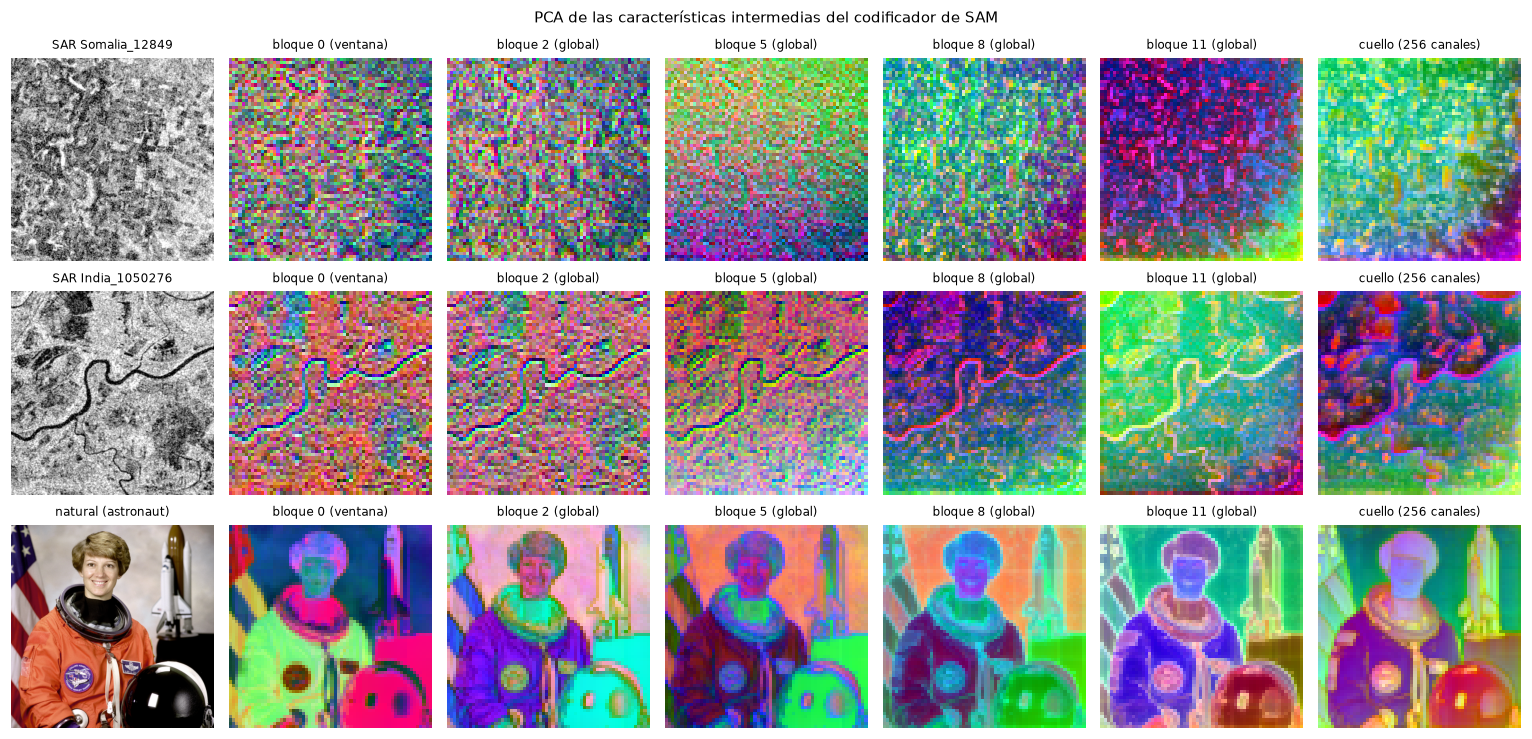

In [8]:
from skimage import data as skdata


def natural_image():
    for name in ("astronaut", "coffee", "chelsea"):
        try:
            img = getattr(skdata, name)()
            from skimage.transform import resize
            return name, (resize(img, (512, 512), anti_aliasing=True) * 255).astype(np.uint8)
        except Exception as exc:
            print("sin", name, exc)
    return "ruido", np.random.default_rng(0).integers(0, 255, (512, 512, 3), dtype=np.uint8)


nat_name, nat = natural_image()
LAYERS = [0, 2, 5, 8, 11]
imgs = {}
for chip in ("Somalia_12849", "India_1050276"):
    dd = data.load_chip(chip)
    imgs[f"SAR {chip}"] = SamWrapper.sar_to_rgb(dd["vv"], dd["vh"])
imgs[f"natural ({nat_name})"] = nat

fig, axes = plt.subplots(len(imgs), len(LAYERS) + 2, figsize=(14, 2.3 * len(imgs)))
for r, (name, rgb) in enumerate(imgs.items()):
    pr = sam.preprocess(rgb)
    emb, states = faseA.encoder_states(model, pr["pixel_values"], LAYERS)
    axes[r, 0].imshow(rgb)
    axes[r, 0].set_title(name, fontsize=8)
    for c, L in enumerate(LAYERS):
        im, _ = faseA.pca_rgb(states[L])
        axes[r, c + 1].imshow(im, interpolation="nearest")
        tipo = "global" if L in vc.global_attn_indexes else "ventana"
        axes[r, c + 1].set_title(f"bloque {L} ({tipo})", fontsize=8)
    im, _ = faseA.pca_rgb(emb[0].permute(1, 2, 0))
    axes[r, -1].imshow(im, interpolation="nearest")
    axes[r, -1].set_title("cuello (256 canales)", fontsize=8)
for a in axes.ravel():
    a.axis("off")
plt.suptitle("PCA de las características intermedias del codificador de SAM", fontsize=10)
plt.tight_layout()
plt.savefig(config.FIG_DIR / "faseA_caracteristicas_pca.png")
plt.show()

## 5. Mapa del campo receptivo efectivo

Para el token central (32, 32) se calcula |∂ Σ_c h_l(32,32,c) / ∂ x|, la magnitud del gradiente de su salida en el bloque *l* respecto de cada píxel de entrada, promediada sobre tres chips SAR. Teoría (configuración real): los bloques 0 y 1 atienden solo dentro de su ventana de 14×14 tokens (tokens 28 a 41, píxeles 448 a 671 en el marco de 1024). El bloque 2 es el primero global.

In [9]:
ERF_LAYERS = [1, 2, 5, 11]
erf_chips = ["India_1050276", "Mekong_1149855", "Somalia_12849"]
erf = {L: np.zeros((1024, 1024)) for L in ERF_LAYERS}
t0 = time.perf_counter()
for chip in erf_chips:
    dd = data.load_chip(chip)
    pr = eager.preprocess(SamWrapper.sar_to_rgb(dd["vv"], dd["vh"]))
    for L in ERF_LAYERS:
        erf[L] += faseA.effective_receptive_field(eager.model, pr["pixel_values"], L) / len(erf_chips)
print(f"Campo receptivo efectivo calculado en {(time.perf_counter()-t0)/60:.1f} min")
ext = {L: faseA.erf_extent(erf[L]) for L in ERF_LAYERS}
pd.DataFrame(ext).T

Campo receptivo efectivo calculado en 0.1 min


,pixeles_95pct_masa,lado_equivalente_px,bbox_gradiente_no_nulo_yx
1,28457,168.692027,"(448, 671, 448, 671)"
2,422840,650.261486,"(0, 1023, 0, 1023)"
5,567622,753.406929,"(0, 1023, 0, 1023)"
11,695744,834.112702,"(0, 1023, 0, 1023)"


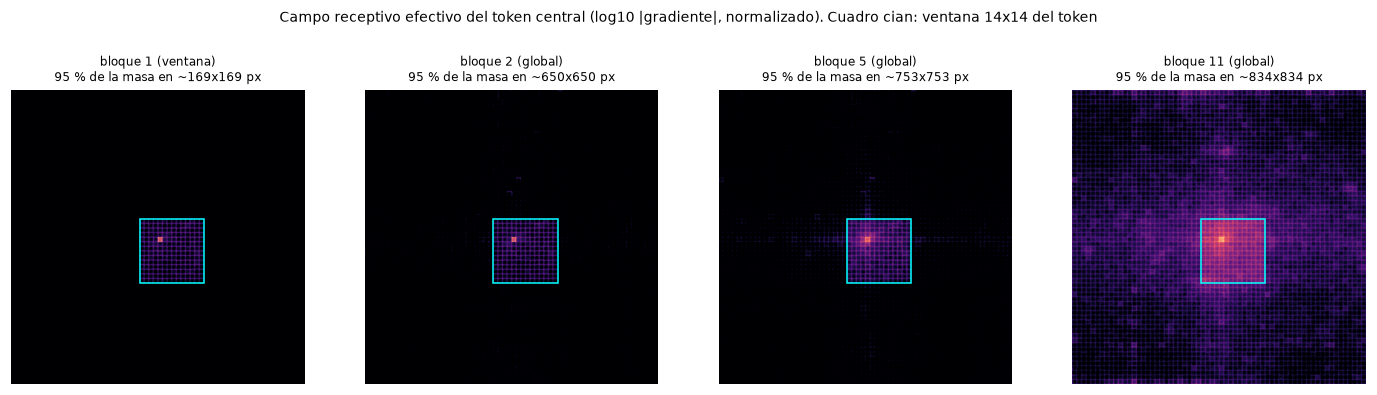

In [10]:
fig, axes = plt.subplots(1, len(ERF_LAYERS), figsize=(13, 3.6))
for a, L in zip(axes, ERF_LAYERS):
    m = erf[L] / erf[L].max()
    a.imshow(np.log10(m + 1e-6), cmap="magma", vmin=-4, vmax=0)
    a.add_patch(plt.Rectangle((448, 448), 224, 224, fill=False, ec="cyan", lw=1))
    tipo = "global" if L in vc.global_attn_indexes else "ventana"
    a.set_title(f"bloque {L} ({tipo})\n95 % de la masa en ~{ext[L]['lado_equivalente_px']:.0f}x{ext[L]['lado_equivalente_px']:.0f} px", fontsize=8)
    a.axis("off")
plt.suptitle("Campo receptivo efectivo del token central (log10 |gradiente|, normalizado). Cuadro cian: ventana 14x14 del token", fontsize=9)
plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.savefig(config.FIG_DIR / "faseA_campo_receptivo_efectivo.png")
plt.show()
RESULT["campo_receptivo_efectivo"] = {"token": [32, 32], "chips": erf_chips, "extension": ext}

## 6. El decodificador y sus tres candidatas

Con `multimask_output=True` el decodificador devuelve tres máscaras: subparte, parte y objeto completo, cada una con su IoU predicho. En la imagen natural representan niveles de un mismo objeto. En el SAR se puede ver qué candidata elige la regla de mayor IoU predicho del pipeline v2.

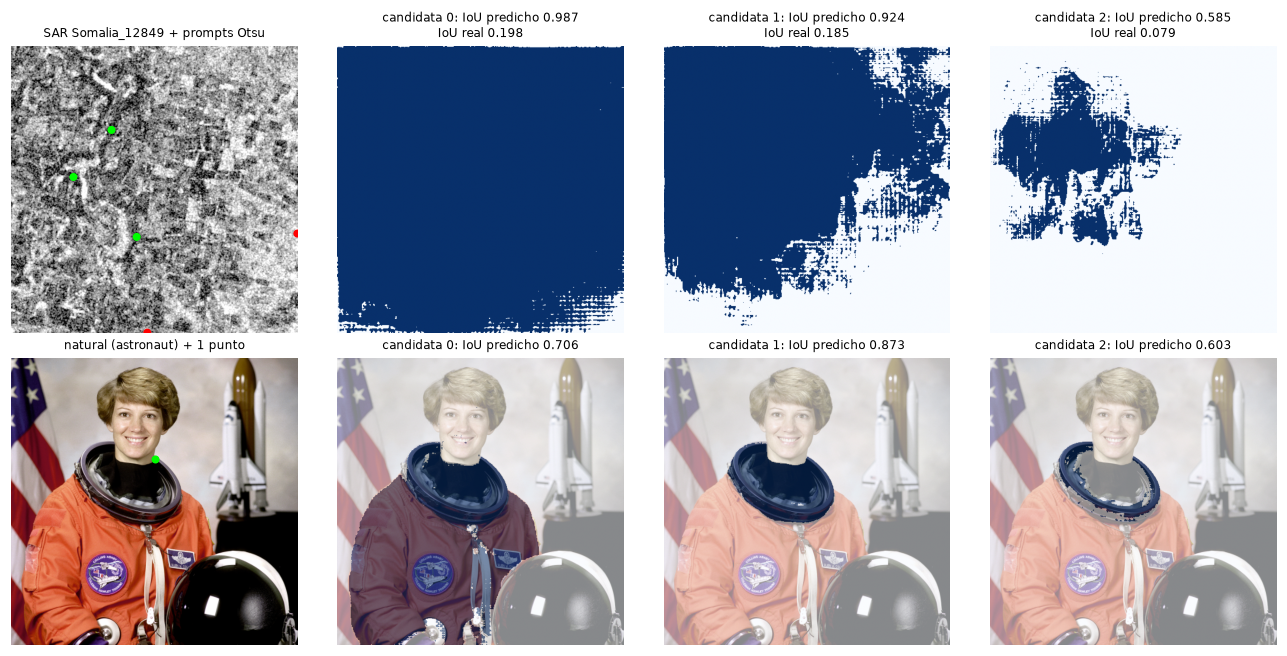

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
lab = d["label"]
r = sam.decode(sam.embed(pre["pixel_values"]), pts, lbs, pre["original_sizes"], pre["reshaped_input_sizes"])
axes[0, 0].imshow(SamWrapper.sar_to_rgb(d["vv"], d["vh"]))
axes[0, 0].scatter([q[0] for q in pts], [q[1] for q in pts], c=["lime" if v == 1 else "red" for v in lbs], s=18)
axes[0, 0].set_title(f"SAR {chip_ref} + prompts Otsu", fontsize=8)
for k in range(3):
    iou_k = iou_components(r["masks"][k], lab == 1, lab != -1)["iou"]
    axes[0, k + 1].imshow(r["masks"][k], cmap="Blues")
    axes[0, k + 1].set_title(f"candidata {k}: IoU predicho {r['scores'][k]:.3f}\nIoU real {iou_k:.3f}", fontsize=8)
pn = sam.preprocess(nat)
pt_nat = [(256, 180)]
rn = sam.decode(sam.embed(pn["pixel_values"]), pt_nat, [1], pn["original_sizes"], pn["reshaped_input_sizes"])
axes[1, 0].imshow(nat)
axes[1, 0].scatter([pt_nat[0][0]], [pt_nat[0][1]], c="lime", s=18)
axes[1, 0].set_title(f"natural ({nat_name}) + 1 punto", fontsize=8)
for k in range(3):
    axes[1, k + 1].imshow(nat)
    axes[1, k + 1].imshow(rn["masks"][k], cmap="Blues", alpha=0.55)
    axes[1, k + 1].set_title(f"candidata {k}: IoU predicho {rn['scores'][k]:.3f}", fontsize=8)
for a in axes.ravel():
    a.axis("off")
plt.tight_layout()
plt.savefig(config.FIG_DIR / "faseA_candidatas_decodificador.png")
plt.show()

In [12]:
del eager
save_json(RESULT, config.RESULTS_DIR / "faseA_diseccion_v3.json")
print("Guardado:", config.RESULTS_DIR / "faseA_diseccion_v3.json")

Guardado: <REPO>\results\faseA_diseccion_v3.json
